# Тема 1. Моделирование геометрической вероятности
## Задание
Смоделируйте вычисление геометрической вероятности (на примере из лекции про метание дротиков в игровой круг, площадь которого в два раза меньше площади стены). Показать теоретический расчет и графическую иллюстрацию для рассматриваемого примера.
### Задача "Зона электромагнитного подавления в институте Р."
В левом крыле второго этажа института Р., план которого представляет собой прямоугольник длиной $a = 60$ м и шириной $b = 20$ м. Непосредственно над ним, на третьем этаже, располагается лаборатория кафедры физики. В лаборатории функционирует сверхпроводящий магнитный резонатор, побочным эффектом работы которого является локальное экранирование радиочастот. Проекция данной «слепой зоны» на плоскость второго этажа образует круг. Согласно плану здания, зона подавления связи строго вписана в ширину левого крыла, радиус круга составляет $R = 9$ м. Требуется определить вероятность того, что в случайно выбранной точке левого крыла второго этажа мобильная связь будет функционировать штатно (точка окажется вне зоны действия физического оборудования).

**Теоретический расчет**

Рассмотрим событие $A$ — в случайно выбранной точке левого крыла мобильная связь функционирует штатно.

По формуле геометрической вероятности делим благоприятную площадь $S_A$ на всю площадь крыла $S$:   

$$P(A) = \frac{S_A}{S}$$

* $S$: размер крыла $60 \times 20$ м:
$$S = 60 \cdot 20 = 1200 \text{ м}^2$$
* $S_A$: площадь зоны уверенного приема рассчитывается как разность общей площади этажа и площади зоны подавления (круга радиусом $9$ м):

$$S_A = 1200 - \pi \cdot 9^2 = 1200 - 81\pi \text{ м}^2$$

$$P(A) = \frac{1200 - 81\pi}{1200} = 1 - \frac{27\pi}{400} \approx 0.7879$$

Экспериментальная вероятность: 0.7834
Теоретическая вероятность: 0.7879


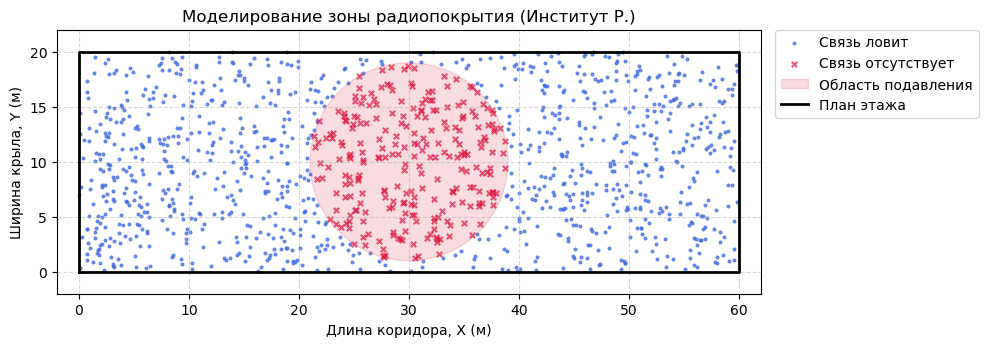

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Параметры плана и зоны подавления
a = 60.0       # длина крыла (м)
b = 20.0       # ширина крыла (м)
R = 9.0        # радиус зоны подавления связи (м)
N = 15000      # количество симулированных точек

# Центр зоны подавления (предположим расположение по центру крыла)
x_c, y_c = a / 2, b / 2 

np.random.seed(42)

# Случайное распределение точек по площади этажа
x = np.random.uniform(0, a, N)
y = np.random.uniform(0, b, N)

# Проверка условия нахождения вне зоны радиуса R
has_signal = (x - x_c)**2 + (y - y_c)**2 > R**2

# Расчет экспериментальной вероятности
P_exp = np.sum(has_signal) / N
P_theory = 1 - (81 * np.pi) / 1200

print(f"Экспериментальная вероятность: {P_exp:.4f}")
print(f"Теоретическая вероятность: {P_theory:.4f}")

# Визуализация
fig, ax = plt.subplots(figsize=(10, 4))

# Для оптимизации графика выводим случайную подвыборку точек
sample_size = 1000
idx_signal = np.random.choice(np.where(has_signal)[0], sample_size, replace=False)
idx_no_signal = np.random.choice(np.where(~has_signal)[0], int(sample_size * 0.25), replace=False)

ax.scatter(x[idx_signal], y[idx_signal], color='royalblue', alpha=0.7, s=15, marker='.', label='Связь ловит')
ax.scatter(x[idx_no_signal], y[idx_no_signal], color='crimson', alpha=0.7, s=15, marker='x', label='Связь отсутствует')

# Отрисовка зоны ЭМИ
theta = np.linspace(0, 2*np.pi, 100)
ax.fill(x_c + R*np.cos(theta), y_c + R*np.sin(theta), color='crimson', alpha=0.15, label='Область подавления')

# Отрисовка границ крыла института
ax.plot([0, a, a, 0, 0], [0, 0, b, b, 0], color='black', lw=2, label='План этажа')

plt.xlim(-2, a + 2)
plt.ylim(-2, b + 2)
plt.title('Моделирование зоны радиопокрытия (Институт Р.)')
plt.xlabel('Длина коридора, X (м)')
plt.ylabel('Ширина крыла, Y (м)')

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.grid(True, linestyle='--', alpha=0.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()

plt.show()